# Code Reference

Saving bits of code that do a specific thing, might turn into a function?

In [ ]:
# population['yearly'].loc['Parker Water and Sanitation District'].to_clipboard()v

In [ ]:
def plt_test(x,y,**kwargs):
    '''
    if including in an existing figure, pass home axes into kwarg 'ax'
    '''
    if not plt.get_fignums():
        fig, ax = plt.subplots()
    else:
        ax = kwargs.get('ax')
    axPlotter = ax
    axPlotter.plot(x,y)
    axPlotter2 = axPlotter.twinx()
    axPlotter2.plot(x,y**2)

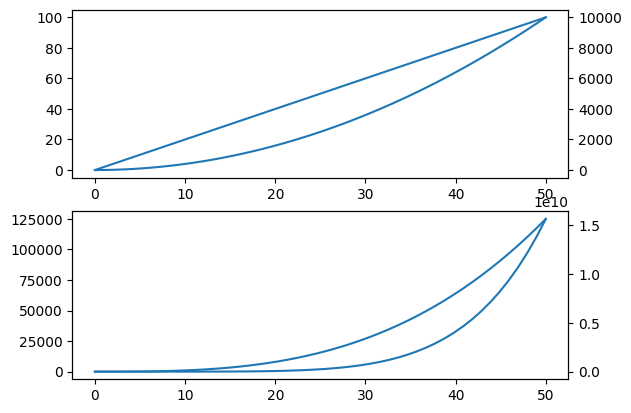

In [ ]:
x = np.linspace(0,50)
y = x*2
# not plt.get_fignums
fig, ax = plt.subplots(2)
plt_test(x,y,ax=ax[0])
plt_test(x,x**3,ax=ax[1])

# fig = plt.figure()
# ax1 = plt_test(x,y)
# ax2 = plt_test(x,x*5)
# ax.set_xlabel('x')
# # fig.add_axes()
# # ax1 = fig.add_axes(plt_test(x,y))
# fig.axes

In [ ]:
list(gds.data.flatten().keys())
# 'geoda.grid100'
# 'geoda.natregimes'
# 'geoda.us_sdoh'
# 'naturalearth.cities'
# 'naturalearth.lakes'
# 'naturalearth.land'

gpd.read_file(gds.get_path('naturalearth.land')).plot()

In [ ]:
# filter df for a value (or na) in any column

providers.loc[providers.isna().any(axis=1)]

In [ ]:
# pull out duplicates from a df

dups = pd.DataFrame({'dups': comments.index.duplicated(keep=False)})
comments.reset_index().join(dups).set_index('dups').loc[True]

# made MUCH easier by just doing:

comments.loc[comments.index.duplicated(keep=False), :]

In [ ]:
# Restrictions (each month) OLD CODE, BETTER WAY TO DO THIS IN THE ANALYSIS

restrictions_idx = ['DNR 1051 Report Name', 'Month']
restrictions = pd.DataFrame(columns=restrictions_idx + ['Restriction', 'Reason'])#.set_index(restrictions_idx)

drop_cols=[]
ct = 1
for m in month_list:
    col_name = ['DNR 1051 Report Name', m + ' Restriction Type', m + ' Reason'] # 'Drought Status Comments'
    arr = metered.loc[['Drought Status']].loc[metered[m + ' Restriction Type'].notna()].reset_index().filter(axis=1, items=col_name)
    arr = arr.loc[~arr.duplicated(), :].rename(columns={m + ' Restriction Type': 'Restriction', m + ' Reason': 'Reason'})
    arr.insert(loc=1, column='Month', value=f'{ct:02}' + '-' + m)
    drop_cols=drop_cols + [m + ' Restriction Type', m + ' Reason']
    if ct == 1:
        restrictions = arr
    else:
        restrictions = pd.concat([restrictions, arr])
    ct += 1

metered.drop(columns=drop_cols, inplace=True)

restrictions = restrictions.set_index(restrictions_idx).sort_index()
restrictions

Restriction  \
DNR 1051 Report Name Month                          
R-000001             01-January    No Restriction   
                     02-February   No Restriction   
                     03-March      No Restriction   
                     04-April      No Restriction   
                     05-May             Mandatory   
...                                           ...   
R-000578             05-May                   NaN   
                     06-June                  NaN   
                     07-July                  NaN   
                     08-August                NaN   
                     09-September             NaN   

                                                                Reason  
DNR 1051 Report Name Month                                              
R-000001             01-January                                    NaN  
                     02-February                                   NaN  
                     03-March                                      NaN  
                     04-April                                      NaN  
                     05-May        Other - please describe in comments  
...                                                                ...  
R-000578             05-May                                        NaN  
                     06-June                                       NaN  
                     07-July                                       NaN  
                     08-August                                     NaN  
                     09-September                                  NaN  

[2594 rows x 2 columns]

In [ ]:
# OLD Metered Use (each month) 
# THIS IS OLD CODE BUT KEEPING IT AROUND FOR POSTERITY BC I FOUND A MUCH BETTER WAY TO DO THIS

# metered_idx = [i for i in metered_idx if i != 'Record Type']

# temp_tbl = pd.DataFrame(columns=metered_idx + ['Month', 'Metered Use'])
# ct = 1
# for m in month_list:
#     col_name = [m + ' Metered Use']
#     arr = metered.loc['Metered Water Use'].filter(axis=1, items=col_name).reset_index().rename(columns={m + ' Metered Use': 'Metered Use'})
#     arr.insert(loc=3, column='Month', value=f'{ct:02}' + '-' + m)
#     if ct == 1:
#         temp_tbl = arr
#     else:
#         temp_tbl = pd.concat([temp_tbl, arr])
#     ct += 1

# metered = temp_tbl.set_index(metered_idx).sort_index()
# metered

In [ ]:
# pivot table
# res_metered.reset_index('Customer Category').pivot_table(columns='Customer Category')

In [ ]:
# # cool way to make multi index
# # Source - https://stackoverflow.com/questions/21443963/pandas-multilevel-column-names
# # Posted by Carl
# # Retrieved 2025-11-05, License - CC BY-SA 4.0

# In [46]: d = {}

# In [47]: d['first_level'] = pd.DataFrame(columns=['idx', 'a', 'b', 'c'],
#                                          data=[[10, 0.89, 0.98, 0.31],
#                                                [20, 0.34, 0.78, 0.34]]).set_index('idx')

# In [48]: pd.concat(d, axis=1)
# Out[48]:
#     first_level
#               a     b     c
# idx
# 10         0.89  0.98  0.31
# 20         0.34  0.78  0.34

# # Source - https://stackoverflow.com/questions/21443963/pandas-multilevel-column-names
# # Posted by Carl
# # Retrieved 2025-11-05, License - CC BY-SA 4.0

# In [49]: d['second_level'] = pd.DataFrame(columns=['idx', 'a', 'b', 'c'],
#                                           data=[[10, 0.29, 0.63, 0.99],
#                                                 [20, 0.23, 0.26, 0.98]]).set_index('idx')

# In [50]: pd.concat(d, axis=1)
# Out[50]:
#     first_level             second_level
#               a     b     c            a     b     c
# idx
# 10         0.89  0.98  0.31         0.29  0.63  0.99
# 20         0.34  0.78  0.34         0.23  0.26  0.98
